# اختبار الإخفاء (masking) لنموذج Stage 2 على الـ hold-out
يقارن هبوط الثقة عند إخفاء منطقة Grad-CAM مقابل إخفاء منطقة عشوائية بنفس المساحة والشكل.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
حجم الـ hold-out: 101
      subset area   n  mean_drop_CAM  mean_drop_random  diff  diff_CI_low  diff_CI_high  wilcoxon_p  flip_CAM  flip_random  frac_images_CAM_worse
         all  10% 101          0.166             0.017 0.149        0.119         0.179         0.0     0.218        0.048                  0.921
         all  20% 101          0.233             0.037 0.196        0.160         0.233         0.0     0.307        0.063                  0.911
         all  30% 101          0.313             0.055 0.258        0.220         0.299         0.0     0.436        0.087                  0.891
correct only  10%  85          0.154             0.015 0.139        0.104         0.176         0.0     0.129        0.026                  0.918
correct only  20%  85          0.223             0.034 0.189        0.148         0.232         0.0     0.235        0.

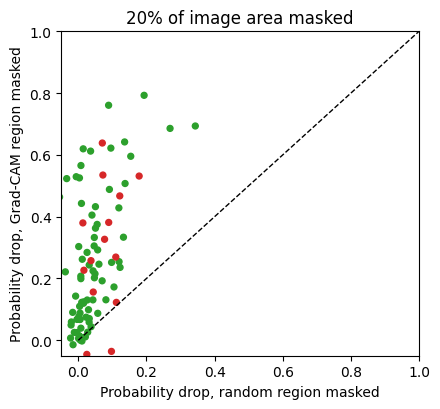

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/skin_disease_project"
CKPT = f"{PROJECT_DIR}/stage2_leprosy_subtype_v2/checkpoints/imagenet_foldFINAL_best.pt"
SPLIT = "/content/drive/MyDrive/stage2_split_v2.csv"
OUT = f"{PROJECT_DIR}/stage2_leprosy_subtype_v2/plots"; os.makedirs(OUT, exist_ok=True)
CLASSES = ["Leprosy Tuberculoid", "Leprosy Lepromatous", "Leprosy Borderline"]
IMG, FRACS, N_RANDOM, SEED = 300, [0.10, 0.20, 0.30], 10, 42
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED); rng = np.random.default_rng(SEED)

m = models.efficientnet_b3(weights=None)
m.classifier = nn.Sequential(nn.Dropout(p=0.4), nn.Linear(m.classifier[1].in_features, 3))
m.load_state_dict(torch.load(CKPT, map_location=dev)); m.to(dev).eval()
tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(),
                         transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

df = pd.read_csv(SPLIT)
pcol = [c for c in df.columns if "path" in c.lower()][0]
ho = df[df.stage2_role == "holdout"].reset_index(drop=True)
print("حجم الـ hold-out:", len(ho))

store = {}
def fwd(mod, i, o):
    if o.requires_grad:
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
m.features[-1].register_forward_hook(fwd)

def cam_map(x, cls):
    m.zero_grad(); out = m(x); out[0, cls].backward()
    a, g = store["a"][0].detach(), store["g"][0].detach()
    cam = torch.relu((g.mean(dim=(1, 2))[:, None, None] * a).sum(0))[None, None]
    cam = F.interpolate(cam, size=(IMG, IMG), mode="bilinear", align_corners=False)[0, 0]
    return cam

@torch.no_grad()
def prob(x, cls): return F.softmax(m(x), 1)[0, cls].item()

def occlude(x, mask):            # المنطقة المحجوبة = قيمة المتوسط (صفر بعد الـ normalize)
    return x * (1 - mask[None, None].float())

rows = []
for i, r in ho.iterrows():
    x = tf(Image.open(r[pcol]).convert("RGB")).unsqueeze(0).to(dev)
    with torch.no_grad(): p0 = F.softmax(m(x), 1)[0]
    pred = int(p0.argmax()); p_orig = p0[pred].item()
    cam = cam_map(x.clone().requires_grad_(True), pred)
    for f in FRACS:
        thr = torch.quantile(cam.flatten(), 1 - f)
        top = cam >= thr
        p_top = prob(occlude(x, top), pred)
        p_rnd, flips_rnd = [], []
        for _ in range(N_RANDOM):
            dy, dx = rng.integers(0, IMG, 2)
            rm = torch.roll(top, shifts=(int(dy), int(dx)), dims=(0, 1))
            with torch.no_grad(): o = F.softmax(m(occlude(x, rm)), 1)[0]
            p_rnd.append(o[pred].item()); flips_rnd.append(int(o.argmax()) != pred)
        with torch.no_grad(): flip_top = int(m(occlude(x, top)).argmax()) != pred
        rows.append(dict(path=r[pcol], true=r["cls"], pred=CLASSES[pred], correct=CLASSES[pred] == r["cls"],
                         frac=f, p_orig=p_orig, p_top=p_top, p_rand=float(np.mean(p_rnd)),
                         drop_top=p_orig - p_top, drop_rand=p_orig - float(np.mean(p_rnd)),
                         flip_top=flip_top, flip_rand=float(np.mean(flips_rnd))))
res = pd.DataFrame(rows); res.to_csv(f"{OUT}/masking_test_per_image.csv", index=False)

def boot_ci(d, B=2000):
    bs = [rng.choice(d, len(d)).mean() for _ in range(B)]; return np.percentile(bs, [2.5, 97.5])

summ = []
for subset, sub in [("all", res), ("correct only", res[res.correct])]:
    for f in FRACS:
        s = sub[sub.frac == f]; d = s.drop_top - s.drop_rand; lo, hi = boot_ci(d.values)
        summ.append(dict(subset=subset, area=f"{int(f*100)}%", n=len(s),
            mean_drop_CAM=s.drop_top.mean(), mean_drop_random=s.drop_rand.mean(),
            diff=d.mean(), diff_CI_low=lo, diff_CI_high=hi, wilcoxon_p=wilcoxon(d).pvalue,
            flip_CAM=s.flip_top.mean(), flip_random=s.flip_rand.mean(),
            frac_images_CAM_worse=(d > 0).mean()))
summ = pd.DataFrame(summ); summ.to_csv(f"{OUT}/masking_test_summary.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(summ.round(3).to_string(index=False))

s = res[res.frac == 0.20]
plt.figure(figsize=(4.5, 4.2))
plt.scatter(s.drop_rand, s.drop_top, c=np.where(s.correct, "tab:green", "tab:red"), s=18)
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlim(-0.05, 1); plt.ylim(-0.05, 1)
plt.xlabel("Probability drop, random region masked"); plt.ylabel("Probability drop, Grad-CAM region masked")
plt.title("20% of image area masked"); plt.tight_layout()
fp = f"{OUT}/masking_test_scatter.png"; plt.savefig(fp, dpi=300); plt.show()

import shutil; shutil.make_archive("/content/masking_results", "zip", OUT)
from google.colab import files; files.download("/content/masking_results.zip")
